CD704: Exercises, Week 7

17 November 2026

You may need LLM / AI help for the following exercises.


# Exercise 1 (Kernel Ridge Regression). 

Load the $\mathtt{scikit-learn}$ California Housing dataset and select a random subset of size 2000. 
Split this subset into training (80%) and test (20%) sets.

1. Fit a $\mathtt{KernelRidge}$ model with an RBF kernel and default hyperparameters directly
on the unscaled training data, and record the test MSE and $R^2$. Next, build a
pipeline combining $\mathtt{StandardScaler}$ and $\mathtt{KernelRidge}$, evaluate it on the same
split, and compare the results.

2. Using pipelines with $\mathtt{StandardScaler}$, try $\mathtt{KernelRidge}$ with four kernels: $\mathtt{linear}$,
$\mathtt{poly}$, $\mathtt{rbf}$, and $\mathtt{laplacian}$. Use $\mathtt{GridSearchCV}$ or $\mathtt{RandomizedSearchCV}$ to tune the
regularisation parameter alpha along with the kernel parameters ($\mathtt{gamma}$, $\mathtt{degree}$,
$\mathtt{coef0}$. Compare the best test $R^2$ across the four kernels. How does the linear
kernel compare to standard ridge regression?

3. Fix a test set of 1000 instances from the full California Housing dataset. Using your
best tuned RBF pipeline, measure both the fitting time ($\mathtt{.fit()}$) and the prediction
time ($\mathtt{.predict()}$) for training set sizes $N$ growing from 200 to 8000 (for example,
200, 500, 1000, 2000, 4000, 8000). Plot both running times against $N$ (you may need
log–log axes). Do your empirical timings relate to the $O(n^3)$ training complexity in
the lecture?

## Response

### Download and Split the Dataset

In [122]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_squared_error
from sklearn.metrics.pairwise import PAIRWISE_KERNEL_FUNCTIONS, pairwise_kernels
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from timeit import default_timer as timer
import warnings

# Load the california housing dataset and split it into training and test sets.

california = fetch_california_housing(data_home="../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

df = pd.DataFrame(X, columns=california.feature_names)
df = pd.concat([df, pd.DataFrame(y, columns=['target'])], axis=1)

# Select 200 random samples from the dataset
df_sampled = df.sample(n=200, random_state=42)

# Split the sampled dataset into training and test sets
X_sampled = df_sampled.drop(columns=['target'])
y_sampled = df_sampled['target']
X_train, X_test, y_train, y_test = train_test_split(X_sampled, y_sampled, test_size=0.2, random_state=42)

# Convert to numpy arrays
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy().reshape(-1, 1)
y_test = y_test.to_numpy().reshape(-1, 1)


### Part 1. KernelRidge with and without Scaling

#### WITHOUT Scaling

In [123]:
kernelRidge = KernelRidge(alpha=1.0, kernel='rbf', gamma=0.1)
kernelRidge.fit(X_train, y_train)
mse = mean_squared_error(y_test, kernelRidge.predict(X_test))
r2 = kernelRidge.score(X_test, y_test)
print(f"UNSCALED Kernel Ridge MSE: {mse}, R2: {r2}")

UNSCALED Kernel Ridge MSE: 4.585026534705182, R2: -2.94638862454016


#### WITH Scaling

In [124]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kernel_ridge', KernelRidge(alpha=1.0, kernel='rbf', gamma=0.1))
])

pipeline.fit(X_train, y_train)
mse = mean_squared_error(y_test, pipeline.predict(X_test))
r2 = pipeline.score(X_test, y_test)
print(f"SCALED Kernel Ridge MSE: {mse}, R2: {r2}")

SCALED Kernel Ridge MSE: 0.4812939212753811, R2: 0.5857444135590764


#### Comparing the Results

Text here.

### Part 2. Survey of Kernels and Search Methods

In [125]:
kernelRidge = KernelRidge(alpha=1.0, kernel='rbf', gamma=0.1)
print(f"params: {kernelRidge.get_params()}")

params: {'alpha': 1.0, 'coef0': 1, 'degree': 3, 'gamma': 0.1, 'kernel': 'rbf', 'kernel_params': None}


In [126]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kr', KernelRidge())
])

kernels = {
    "linear": {
        "param_grid": {
            'kr__alpha': np.logspace(-5, 3, 9),
            'kr__kernel': ['linear']
        }
    }, 
    "poly": {
        "param_grid": {
            'kr__kernel': ['poly'],
            'kr__gamma': np.logspace(-5, 5, 9),
            'kr__degree': [2, 3, 4, 5]
        }
    },
    "rbf": {
        "param_grid": {
            'kr__kernel': ['rbf'],
            'kr__gamma': np.logspace(-10, 10, 21)
        }
    }, 
    "laplacian": {
        "param_grid": {
            'kr__kernel': ['laplacian'],
            'kr__gamma': np.logspace(-5, 5, 9)
        }
    }
}

gridsearches = {}

for key in kernels.keys():
    curr_kernel = kernels[key]
    print(f"Running grid search for {key} kernel...")
    my_param_grid = kernels[key]["param_grid"]
    my_gridsearch = GridSearchCV(pipeline, param_grid=my_param_grid, cv=5)
    with warnings.catch_warnings(action="ignore"):
        my_gridsearch.fit(X_train, y_train)
    mse = mean_squared_error(y_test, my_gridsearch.predict(X_test))
    r2 = my_gridsearch.score(X_test, y_test)
    print(f"{key} kernel: MSE: {mse}, R2: {r2}")
    gridsearches[key] = my_gridsearch




Running grid search for linear kernel...
linear kernel: MSE: 4.634809501281956, R2: -2.9892374350121096
Running grid search for poly kernel...
poly kernel: MSE: 0.36819034399622835, R2: 0.6830940509909889
Running grid search for rbf kernel...
rbf kernel: MSE: 0.48291866130571226, R2: 0.5843459798695435
Running grid search for laplacian kernel...
laplacian kernel: MSE: 0.4460042333088122, R2: 0.6161186812106798


In [127]:
random_searches = {}

for key in kernels.keys():
    curr_kernel = kernels[key]
    print(f"Running randomized search for {key} kernel...")
    my_param_grid = kernels[key]["param_grid"]
    my_random_search = RandomizedSearchCV(pipeline, param_distributions=my_param_grid, n_iter=10, cv=5, random_state=42)
    with warnings.catch_warnings(action="ignore"):
        my_random_search.fit(X_train, y_train)
    mse = mean_squared_error(y_test, my_random_search.predict(X_test))
    r2 = my_random_search.score(X_test, y_test)
    print(f"{key} kernel: MSE: {mse}, R2: {r2}")
    random_searches[key] = my_random_search

Running randomized search for linear kernel...
linear kernel: MSE: 4.634809501281956, R2: -2.9892374350121096
Running randomized search for poly kernel...
poly kernel: MSE: 0.3731553150326438, R2: 0.6788206394696003
Running randomized search for rbf kernel...
rbf kernel: MSE: 0.48291866130571226, R2: 0.5843459798695435
Running randomized search for laplacian kernel...
laplacian kernel: MSE: 0.4460042333088122, R2: 0.6161186812106798


#### Analysis

Text here.

### Part 3. Checking Runtimes

In [138]:
# Load the california housing dataset
california = fetch_california_housing(data_home="../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

df = pd.DataFrame(X, columns=california.feature_names)
df = pd.concat([df, pd.DataFrame(y, columns=['target'])], axis=1)

# Select 1000 random samples from the dataset
fixed_test_set = df.sample(n=1000, random_state=42)
X_fixed_test = fixed_test_set.drop(columns=['target'])
y_fixed_test = fixed_test_set['target']
X_test = X_fixed_test.to_numpy()
y_test = y_fixed_test.to_numpy().reshape(-1, 1)

X_fixed_test = fixed_test_set.drop(columns=['target'])
y_fixed_test = fixed_test_set['target']

df_remaining = df.drop(fixed_test_set.index)

#training_set_sizes = np.linspace(200, 6000, num=20, dtype=int)
training_set_sizes = np.linspace(3900, 4100, num=50, dtype=int)
#training_set_sizes = np.linspace(200, 8000, num=20, dtype=int)
#training_set_sizes = np.linspace(3000, 6000, num=100, dtype=int)


timings_and_scores = pd.DataFrame(columns=['training_set_size', 'fit_time', 'test_time', 'mse', 'r2'])

for n in training_set_sizes:
    df_sampled = df_remaining.sample(n=n, random_state=42)
    X_sampled = df_sampled.drop(columns=['target'])
    y_sampled = df_sampled['target']

    X_train = X_sampled
    y_train = y_sampled

    # Convert to numpy arrays
    X_train = X_train.to_numpy()
    y_train = y_train.to_numpy().reshape(-1, 1)

    # Train the RBF pipeline
    best_rbf_pipeline = random_searches['rbf'].best_estimator_
    
    fit_timer_start = timer()
    best_rbf_pipeline.fit(X_train, y_train)
    fit_time = timer() - fit_timer_start

    predict_timer_start = timer()
    mse = mean_squared_error(y_test, best_rbf_pipeline.predict(X_test))
    predict_time = timer() - predict_timer_start

    r2 = best_rbf_pipeline.score(X_test, y_test)

    # Append the timing results to the DataFrame
    timings_and_scores = pd.concat([timings_and_scores, pd.DataFrame({'training_set_size': [n], 'fit_time': [fit_time], 'test_time': [predict_time], 'mse': [mse], 'r2': [r2]})], ignore_index=True)

    print(f"Training set size: {n}, RBF kernel: MSE: {mse}, R2: {r2}")

Training set size: 3900, RBF kernel: MSE: 0.43603717340446907, R2: 0.6780277369451211
Training set size: 3904, RBF kernel: MSE: 0.43598114054084874, R2: 0.6780691119218563
Training set size: 3908, RBF kernel: MSE: 0.4360276699550194, R2: 0.6780347543448126
Training set size: 3912, RBF kernel: MSE: 0.4360976619253812, R2: 0.677983071886372
Training set size: 3916, RBF kernel: MSE: 0.43610536503177727, R2: 0.6779773838699592
Training set size: 3920, RBF kernel: MSE: 0.4361490291918447, R2: 0.6779451420124096
Training set size: 3924, RBF kernel: MSE: 0.4361369431072342, R2: 0.6779540664442031
Training set size: 3928, RBF kernel: MSE: 0.47764467912167324, R2: 0.6473045243546881
Training set size: 3932, RBF kernel: MSE: 0.4776324235647996, R2: 0.6473135739257391
Training set size: 3936, RBF kernel: MSE: 0.47755903604260597, R2: 0.6473677636784525
Training set size: 3940, RBF kernel: MSE: 0.47758187611536285, R2: 0.64735089844227
Training set size: 3944, RBF kernel: MSE: 0.4774815871158867, 

In [139]:
def save_timings_and_scores_to_csv(timings_and_scores):
    """
    Save the timings and scores DataFrame to a CSV file.

    Parameters:
    timings_and_scores (pd.DataFrame): DataFrame containing the timings and scores.
    """

    filename = build_filename_for_timings_and_scores(timings_and_scores)
    timings_and_scores.to_csv(filename, index=False)

def load_timings_and_scores_from_csv(filename):
    """
    Load the timings and scores DataFrame from a CSV file.

    Parameters:
    filename (str): The name of the CSV file to load the DataFrame from.

    Returns:
    pd.DataFrame: DataFrame containing the timings and scores.
    """
    return pd.read_csv(filename)

def build_filename_for_timings_and_scores(df, extension="csv"):
    """
    Build a filename for the timings and scores CSV file based on the DataFrame.

    Parameters:
    df (pd.DataFrame): DataFrame containing the timings and scores.

    Returns:
    str: The constructed filename for the CSV file.
    """

    min_sample_size = df['training_set_size'].min()
    max_sample_size = df['training_set_size'].max()
    num_iterations = df.shape[0]
    filename = f"timings_and_scores_{min_sample_size}_{max_sample_size}_{num_iterations}.{extension}"
    
    return filename

def plot_timings_and_scores(timings_and_scores):
    """
    Plot the timings and scores from the DataFrame.

    Parameters:
    timings_and_scores (pd.DataFrame): DataFrame containing the timings and scores.
    """

    fig, ax1 = plt.subplots(figsize=(6, 6))

    color = 'tab:blue'
    ax1.set_xlabel('Training Set Size')
    ax1.set_ylabel('Fit Time (s)', color=color)
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.plot(timings_and_scores['training_set_size'], timings_and_scores['fit_time'], color=color, label='Fit Time')
    ax1.tick_params(axis='y', labelcolor=color)

    color = 'tab:red'
    ax1.plot(timings_and_scores['training_set_size'], timings_and_scores['test_time'], color=color, label='Test Time')

    ax1.legend(loc='upper left')

    fig.tight_layout()
    plt.title('Fit and Test Times vs Training Set Size')
    plt.show()

In [140]:
# Save the timings and scores to a CSV file
save_timings_and_scores_to_csv(timings_and_scores)

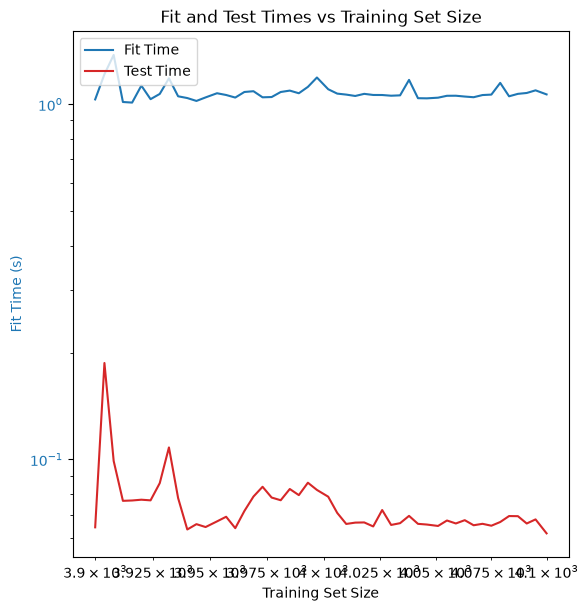

In [141]:
plot_timings_and_scores(timings_and_scores)

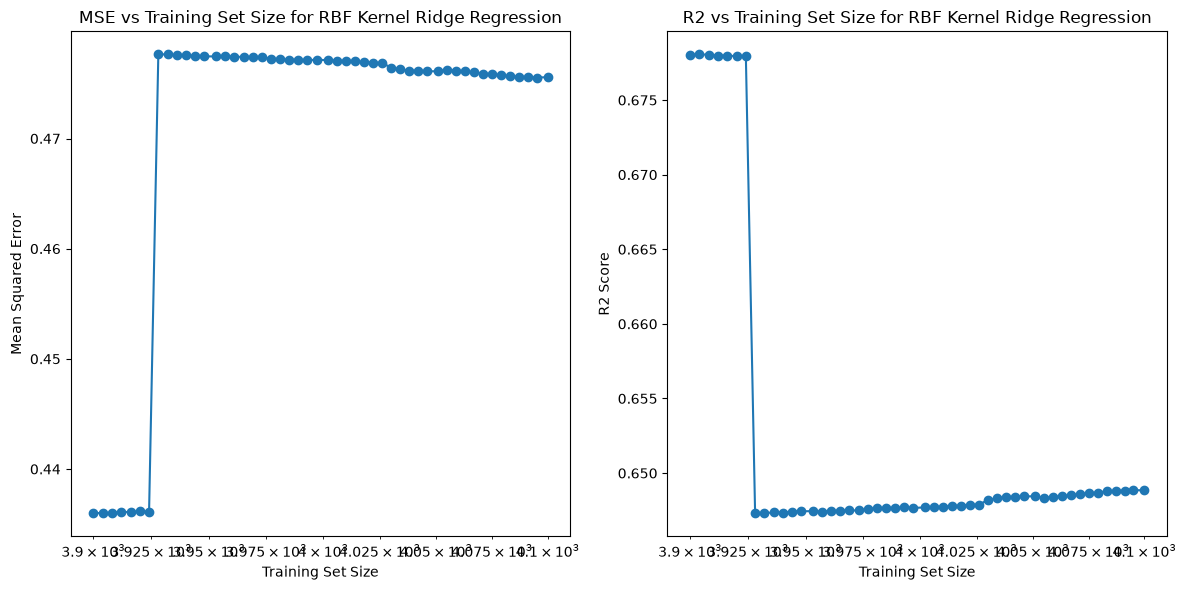

In [142]:
# Plot the MSE and R2 results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(timings_and_scores['training_set_size'], timings_and_scores['mse'], label='MSE', marker='o')
plt.xscale('log')
plt.xlabel('Training Set Size')
plt.ylabel('Mean Squared Error')
plt.title('MSE vs Training Set Size for RBF Kernel Ridge Regression')
plt.subplot(1, 2, 2)
plt.plot(timings_and_scores['training_set_size'], timings_and_scores['r2'], label='R2', marker='o')
plt.xscale('log')
plt.xlabel('Training Set Size')
plt.ylabel('R2 Score')
plt.title('R2 vs Training Set Size for RBF Kernel Ridge Regression')
plt.tight_layout()
filename = build_filename_for_timings_and_scores(timings_and_scores, extension="svg")
plt.savefig(filename, format='svg')
plt.show()

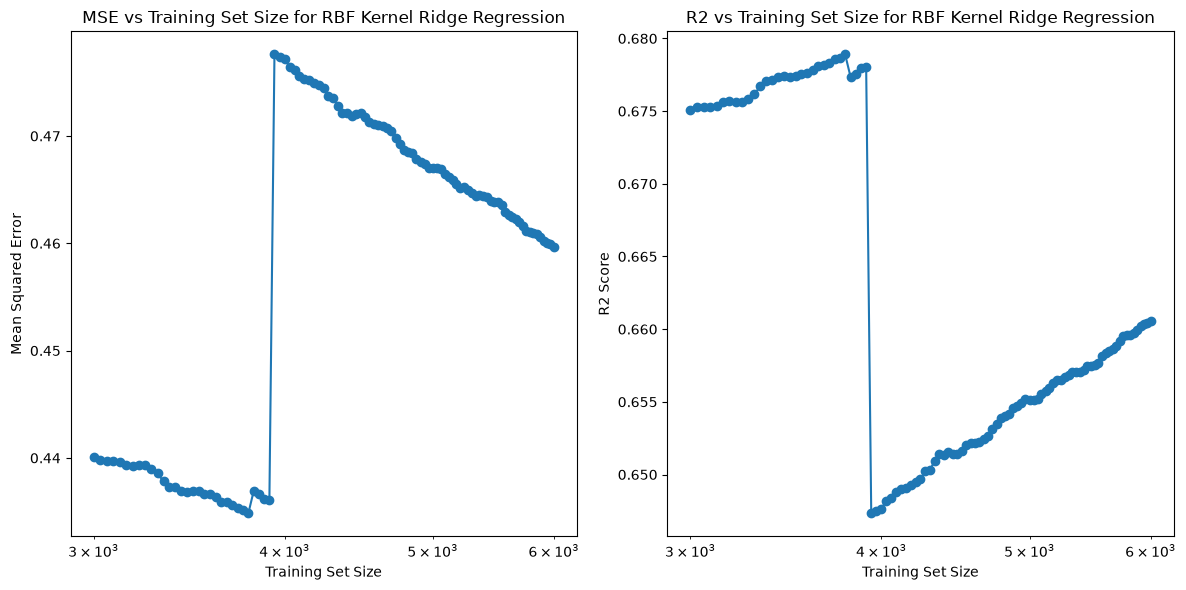

In [148]:
df = load_timings_and_scores_from_csv("timings_and_scores_3000_6000_100.csv")

timings_and_scores = df


# Plot the MSE and R2 results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(timings_and_scores['training_set_size'], timings_and_scores['mse'], label='MSE', marker='o')
plt.xscale('log')
plt.xlabel('Training Set Size')
plt.ylabel('Mean Squared Error')
plt.title('MSE vs Training Set Size for RBF Kernel Ridge Regression')
plt.subplot(1, 2, 2)
plt.plot(timings_and_scores['training_set_size'], timings_and_scores['r2'], label='R2', marker='o')
plt.xscale('log')
plt.xlabel('Training Set Size')
plt.ylabel('R2 Score')
plt.title('R2 vs Training Set Size for RBF Kernel Ridge Regression')
plt.tight_layout()
filename = build_filename_for_timings_and_scores(timings_and_scores, extension="svg")
plt.savefig(filename, format='svg')
plt.show()


# Exercise 2 (Kernel Support Vector Classification). 

Load the scikit-learn Breast Cancer Wisconsin dataset and split it into training (80%) and test (20%) sets using a stratified
split.
1. Inspect the ranges of the features in the dataset. Fit a support vector classifier SVC(kernel="rbf") with default parameters on the unscaled training data
and evaluate its test accuracy (and inspect the predicted classes). Then wrap
StandardScaler and SVC(kernel="rbf") inside a Pipeline, re-evaluate and compare the results.

2. Using pipelines with StandardScaler, try SVC with kernel="linear", kernel="poly",
and kernel="rbf". Tune the regularisation parameter and kernel parameters via
cross-validation. Compare the test accuracies and the number of support vectors
retained by each winning model.




## Response

### Part 1. SVC With and Without Scaling

#### Table Setting

In [133]:
# Download the Breast Cancer Wisconsin dataset
def load_breast_cancer_dataset():
    """
    Load the Breast Cancer Wisconsin dataset.

    Returns:
    tuple: A tuple containing the features (X) and target (y) of the dataset.
    """
    breast_cancer = load_breast_cancer()
    X_bc = breast_cancer.data
    y_bc = breast_cancer.target
    df_bc = pd.DataFrame(X_bc, columns=breast_cancer.feature_names)
    df_bc = pd.concat([df_bc, pd.DataFrame(y_bc, columns=['target'])], axis=1)
    return df_bc

def produce_stratified_split(df, test_size=0.2, random_state=42):
    """
    Produce a stratified split of the dataset into training and test sets.

    Parameters:
    df (pd.DataFrame): The input DataFrame containing features and target.
    test_size (float): The proportion of the dataset to include in the test split.
    random_state (int): Random seed for reproducibility.

    Returns:
    tuple: A tuple containing the training and test sets (X_train, X_test, y_train, y_test).
    """
    sss = StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    split = sss.split(df.drop('target', axis=1), df['target'])

    X_bc_train, X_bc_test, y_bc_train, y_bc_test = None, None, None, None

    for i, (train_index, test_index) in enumerate(split):
        X_bc_train, X_bc_test = df.drop('target', axis=1).iloc[train_index], df.drop('target', axis=1).iloc[test_index]
        y_bc_train, y_bc_test = df['target'].iloc[train_index], df['target'].iloc[test_index]
    
    return X_bc_train, X_bc_test, y_bc_train, y_bc_test

df_bc = load_breast_cancer_dataset()
X_bc_train, X_bc_test, y_bc_train, y_bc_test = produce_stratified_split(df_bc)

#### Some Notes on the Values in the Dataset

Text here.

#### WITHOUT Scaling

In [134]:
svc = SVC(kernel='rbf', C=1.0, gamma='scale')
fitted_svc = svc.fit(X_bc_train, y_bc_train)
mse = mean_squared_error(y_bc_test, fitted_svc.predict(X_bc_test))
r2 = fitted_svc.score(X_bc_test, y_bc_test)
print(f"SVC RBF kernel: MSE: {mse}, R2: {r2}")

SVC RBF kernel: MSE: 0.07017543859649122, R2: 0.9298245614035088


#### WITH Scaling

Further reading: 
+ clementine

+ knime

In [135]:
svc = SVC(kernel='rbf', C=1.0, gamma='scale')
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', svc)
])
pipeline.fit(X_bc_train, y_bc_train)
mse = mean_squared_error(y_bc_test, pipeline.predict(X_bc_test))
r2 = pipeline.score(X_bc_test, y_bc_test)
print(f"SVC RBF kernel with scaling: MSE: {mse}, R2: {r2}")

SVC RBF kernel with scaling: MSE: 0.017543859649122806, R2: 0.9824561403508771


### Part 2. SVC with a Variety of Kernels

In [136]:
kernels = ['linear', 'poly', 'rbf']

for kernel in kernels:
    svc = SVC(kernel=kernel, C=1.0, gamma='scale')
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svc', svc)
    ])
    my_random_search = RandomizedSearchCV(pipeline, param_distributions={'svc__C': np.logspace(-3, 3, 20), 'svc__gamma': np.logspace(-3, 3, 20)}, n_iter=10, cv=5, random_state=42)
    with warnings.catch_warnings(action="ignore"):
        my_random_search.fit(X_bc_train, y_bc_train)
    mse = mean_squared_error(y_bc_test, my_random_search.predict(X_bc_test))
    r2 = my_random_search.score(X_bc_test, y_bc_test)
    print(f"SVC {kernel} kernel: MSE: {mse}, R2: {r2}")

    # Print the number of support vectors for each class
    best_svc = my_random_search.best_estimator_.named_steps['svc']
    print(f"Number of support vectors for {kernel} kernel: {best_svc.n_support_}")


SVC linear kernel: MSE: 0.017543859649122806, R2: 0.9824561403508771
Number of support vectors for linear kernel: [26 28]
SVC poly kernel: MSE: 0.02631578947368421, R2: 0.9736842105263158
Number of support vectors for poly kernel: [24 38]
SVC rbf kernel: MSE: 0.017543859649122806, R2: 0.9824561403508771
Number of support vectors for rbf kernel: [31 32]


# Exercise 3 (Kernels and Explainability). 

Load the scikit-learn Breast Cancer Wisconsin dataset and split it into training (80%) and test (20%) sets using a stratified
split.

1. Build pipelines with $\mathtt{StandardScaler}$ for a linear SVM and an SVM with an RBF
kernel. Compare their test accuracies. For the linear model, extract and plot the
top 10 features with the largest absolute weights $|w_j|$. Note that the linear decision
score $\vec w^T \vec x + w_0$ decomposes directly into exact feature contributions $w_j x_j$
for any
standardised input $\vec x$.

2. Using the $\mathtt{lime}$ package, generate local explanations for three test instances: a
confident benign prediction, a confident malignant prediction, and a borderline or
misclassified instance. Do this for both the linear pipeline and the RBF SVM
pipeline (passing the pipeline’s .predict proba method so features remain in their
original units). Compare LIME’s feature weights for the linear model with the exact
contributions wjxj, and check how much LIME explanations vary if you re-run the
explainer with a different random seed.

3. Using the shap package, compute SHAP values for both pipelines (for example, using shap.Explainer on the linear model and shap.KernelExplainer with a summarised background set such as shap.kmeans(X train, 25) for the RBF SVM).
Produce a SHAP summary plot across the test set and waterfall plots for the same
three instances examined before. Compare the global feature importance ranking
of the RBF SVM with the linear model weights above.

## Response

### Part 1. The Explainability (and Efficacy) of Linear Kernels

In [137]:
df_bc = load_breast_cancer_dataset()
X_bc_train, X_bc_test, y_bc_train, y_bc_test = produce_stratified_split(df_bc)

# Build and fit the SVC model with RBF and linear kernels, and compare their performance using MSE and R2 scores.
kernels = ['linear', 'rbf']

for kernel in kernels:
    svc = SVC(kernel=kernel, C=1.0, gamma='scale')
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svc', svc)
    ])
    my_random_search = RandomizedSearchCV(pipeline, param_distributions={'svc__C': np.logspace(-3, 3, 20), 'svc__gamma': np.logspace(-3, 3, 20)}, n_iter=10, cv=5, random_state=42)
    with warnings.catch_warnings(action="ignore"):
        my_random_search.fit(X_bc_train, y_bc_train)
    mse = mean_squared_error(y_bc_test, my_random_search.predict(X_bc_test))
    r2 = my_random_search.score(X_bc_test, y_bc_test)
    print(f"SVC {kernel} kernel: MSE: {mse}, R2: {r2}")

    if kernel == 'linear':
        best_linear_svc = my_random_search.best_estimator_.named_steps['svc']

# Analyze the linear kernel SVC model
print(f"Number of support vectors for linear kernel: {best_linear_svc.n_support_}")
abs_weights = np.abs(best_linear_svc.coef_[0])
feature_names = df_bc.drop(columns=['target']).columns

# Get the indices of the top and bottom n features with the highest absolute weights
n = 10
top_indices = np.argsort(abs_weights)[::-1][:n]
bottom_indices = np.argsort(abs_weights)[:n]

print(f"Top {n} features with the highest absolute weights:")
for i, idx in enumerate(top_indices, start=1):
    print(f"{i}. {feature_names[idx]}: {abs_weights[idx]}")

print(f"\nBottom {n} features with the lowest absolute weights:")
for i, idx in enumerate(bottom_indices, start=1):
    print(f"{i}. {feature_names[idx]}: {abs_weights[idx]}")

SVC linear kernel: MSE: 0.017543859649122806, R2: 0.9824561403508771
SVC rbf kernel: MSE: 0.017543859649122806, R2: 0.9824561403508771
Number of support vectors for linear kernel: [26 28]
Top 10 features with the highest absolute weights:
1. worst texture: 0.44621286761877127
2. worst symmetry: 0.3903092628622704
3. radius error: 0.3507697070424782
4. worst concave points: 0.34291231001357614
5. worst radius: 0.34075598275161684
6. worst area: 0.3235039872800918
7. area error: 0.31403648030267434
8. worst perimeter: 0.2974814186947881
9. mean texture: 0.2900915521982054
10. worst concavity: 0.27557601330425174

Bottom 10 features with the lowest absolute weights:
1. worst compactness: 0.010711597502794962
2. concavity error: 0.03212651044799075
3. mean smoothness: 0.07415662796437024
4. worst fractal dimension: 0.09328132472459157
5. smoothness error: 0.09351818568854792
6. texture error: 0.09531763697776714
7. symmetry error: 0.10367980817419824
8. fractal dimension error: 0.104473394